# **Predict Hotel Booking Cancellation Probability**
**ESE 5420 — Stats for Data Science, Fall 2026**

**Team Members**:
- Fenting Jin (ivyjin@engineering.upenn.edu)
- Shen Li (lishen18@engineering.upenn.edu )
- Yining Liang (yinil22@engineering.upenn.edu)

## Section 1 — Introduction & Background
### Problem statement
A confirmed hotel reservation does not always become an occupied room. When guests cancel, hotels may lose opportunities to sell rooms to other customers, especially when cancellations occur close to arrival. However, treating every reservation as equally likely to cancel can also lead to poor planning.

Thus, the central question is how we could utilize reservation characteristics, such as booking lead time, distribution channel, stay length, and previous booking history to predict hotel booking cancellations. For better prediction, we also want to know how different classification models compare in making those predictions.

### Value proposition
A cancellation prediction model provides a risk estimate for each reservation, giving hotel managers more information than an overall historical cancellation rate. With limited staff time, managers could prioritize a subset of reservations for review rather than treating all bookings equally.

As an optional descriptive illustration, we can examine how many cancellations fall within the highest-risk 20% of bookings for each arrival date. This is not a model-selection metric. It does not establish that contacting guests would prevent cancellations or increase hotel profits.

### Approach
We build a classification pipeline with four stages:

1. **Data preparation**: combine the city and resort hotel datasets, clean categorical values, handle missing information, and document unusual records.
2. **Feature preparation**: exclude outcome-revealing fields, encode categorical variables, and create features describing booking timing, party size, and stay characteristics.
3. **Model comparison**: train a ridge-penalized Logistic Regression baseline, a single Decision Tree, and a Random Forest, tuned on expanding arrival-date windows within the development period.
4. **Evaluation and interpretation**: compare probability quality (log loss, with ROC-AUC as a secondary ranking metric) and interpret the fitted models. Paired block-bootstrap intervals over arrival-date blocks assess differences between models.

We split the data in time order by scheduled arrival date, because the data contain no reliable booking-creation date. Our target is a cancellation forecast made at booking time, but the fields are snapshots taken the day before arrival, so this can only be approximated (see below).

- **Train**: 78,590 bookings with arrivals from July 2015 through December 2016.
- **Validation**: four expanding windows within the development period, validating on Jan–Mar, Apr–Jun, Jul–Sep and Oct–Dec 2016, always training from 1 July 2015.
- **Test**: arrivals from 1 January to 31 August 2017, removed from modeling and sealed until all tuning is finished.

After model development, all pipelines are refitted on the complete development set and scored once on the sealed test set. We use mean validation log loss to tune models and test log loss as the **primary model-comparison outcome**; ROC-AUC is secondary. Threshold metrics (precision, recall, F1, accuracy at threshold=0.5) and the confusion matrix are diagnostics reported in an appendix, not comparison metrics.

### Datasets
We use the public [***Hotel Booking Demand Datasets***](https://www.sciencedirect.com/science/article/pii/S2352340918315191?via%3Dihub#s0010) published by Antonio, de Almeida, and Nunes (2019):

- `H1.csv` — 40,060 bookings from a resort hotel.
- `H2.csv` — 79,330 bookings from a city hotel.

The original files contain 119,390 bookings, each described by 31 variables. We add a hotel-type indicator when combining them. After removing 180 zero-guest records and one negative-ADR record, 119,209 bookings remain; extreme positive ADR values are reviewed rather than automatically discarded.

The authors removed hotel and customer identification information. The data accompany an article distributed under CC BY 4.0, permitting reuse and publication of attributed derived figures.

The goal is to predict at booking time. The data paper, however, builds inputs from the hotel change log as of the day before arrival, so amendments made after booking can appear in the inputs and "known at booking" holds only approximately. We therefore exclude clear outcome and late-update fields and treat the project as a retrospective comparison of historical arrival cohorts, not a validated booking-time deployment.

### Raw variables in the source files

All 31 variables in `H1.csv` and `H2.csv`, as described in the data paper (Antonio et al., 2019, Table 1; descriptions paraphrased). We add one more column, `hotel_type` (Resort Hotel for H1, City Hotel for H2), giving 32 columns. Source tables: BO = bookings, BL = bookings change log, TR = transactions, CP = customer profiles, NT = nationalities, MS = market segments, ML = meals, DC = distribution channels.

| # | Variable (file name) | Notebook name | Type | Description | Source |
|---|---|---|---|---|---|
| 1 | IsCanceled | is_canceled | Categorical | **Target.** 1 if the booking was cancelled, 0 otherwise | BO |
| 2 | LeadTime | lead_time | Integer | Days between entering the booking in the hotel system and the arrival date | BO, BL |
| 3 | ArrivalDateYear | arrival_date_year | Integer | Year of arrival | BO, BL |
| 4 | ArrivalDateMonth | arrival_date_month | Categorical | Month of arrival, January to December | BO, BL |
| 5 | ArrivalDateWeekNumber | arrival_date_week_number | Integer | Week number of the arrival date | BO, BL |
| 6 | ArrivalDateDayOfMonth | arrival_date_day_of_month | Integer | Day of the month of arrival | BO, BL |
| 7 | StaysInWeekendNights | stays_in_weekend_nights | Integer | Weekend nights (Saturday, Sunday) stayed or booked | BO, BL |
| 8 | StaysInWeekNights | stays_in_week_nights | Integer | Week nights (Monday to Friday) stayed or booked | BO, BL |
| 9 | Adults | adults | Integer | Number of adults | BO, BL |
| 10 | Children | children | Integer | Number of children (payable and non-payable) | BO, BL |
| 11 | Babies | babies | Integer | Number of babies | BO, BL |
| 12 | Meal | meal | Categorical | Meal package booked: Undefined/SC (none), BB, HB, FB | BO, BL, ML |
| 13 | Country | country | Categorical | Country of origin | BO, BL, NT |
| 14 | MarketSegment | market_segment | Categorical | Market segment (TA = travel agents, TO = tour operators) | BO, BL, MS |
| 15 | DistributionChannel | distribution_channel | Categorical | Booking distribution channel | BO, BL, DC |
| 16 | IsRepeatedGuest | is_repeated_guest | Categorical | 1 if a guest profile already existed before this booking was created | BO, BL, CP |
| 17 | PreviousCancellations | previous_cancellations | Integer | Earlier bookings by the same profile that were cancelled (0 if no profile) | BO, BL |
| 18 | PreviousBookingsNotCanceled | previous_bookings_not_canceled | Integer | Earlier bookings by the same profile that were not cancelled (0 if no profile) | BO, BL |
| 19 | ReservedRoomType | reserved_room_type | Categorical | Code of the reserved room type (coded for anonymity) | BO, BL |
| 20 | AssignedRoomType | assigned_room_type | Categorical | Code of the room type actually assigned; can differ from the reserved type through hotel operations (for example overbooking) or customer request | BO, BL |
| 21 | BookingChanges | booking_changes | Integer | Number of amendments (persons, arrival date, nights, room type, meal) from entry in the system until check-in or cancellation | BO, BL |
| 22 | DepositType | deposit_type | Categorical | No Deposit, Non Refund (deposit covers the full stay cost) or Refundable (smaller deposit), from payments made before arrival or cancellation | BO, TR |
| 23 | Agent | agent | Categorical | ID of the travel agency that made the booking (NULL = not applicable) | BO, BL |
| 24 | Company | company | Categorical | ID of the company that made or pays for the booking (NULL = not applicable) | BO, BL |
| 25 | DaysInWaitingList | days_in_waiting_list | Integer | Days between the booking entering the system and its confirmation to the customer | BO |
| 26 | CustomerType | customer_type | Categorical | Contract, Group, Transient or Transient-party | BO, BL |
| 27 | ADR | adr | Numeric | Average daily rate: sum of all lodging transactions divided by the number of nights | BO, BL, TR |
| 28 | RequiredCarParkingSpaces | required_car_parking_spaces | Integer | Number of car parking spaces required by the customer | BO, BL |
| 29 | TotalOfSpecialRequests | total_of_special_requests | Integer | Number of special requests (for example twin bed, high floor) | BO, BL |
| 30 | ReservationStatus | reservation_status | Categorical | Last status: Canceled, Check-Out or No-Show | BO |
| 31 | ReservationStatusDate | reservation_status_date | Date | Date the last status was set | BO |
| 32 | (added by us) | hotel_type | Categorical | Resort Hotel (H1) or City Hotel (H2) | file name |

**Timing note from the paper.** To avoid leakage the authors take each booking's input values from the change log *as of the day before arrival*, while the target comes from the bookings table. This matters for which columns we can safely use (Section 2.6).

### Target variable
The target is `IsCanceled`
- `IsCanceled = 1`: the booking was cancelled.
- `IsCanceled = 0`: the booking was not cancelled.

We treat cancellation as the positive class. Each model estimates a cancellation probability, and the appendix threshold diagnostics use a common 0.5 threshold.

`ReservationStatus` and `ReservationStatusDate` are excluded from the predictor set because they reveal the final outcome or its timing.

### EDA highlights
Exploratory analysis uses the development cohort (arrivals from July 2015 to December 2016); the 2017 test cohort is not examined.

- Cancellations are common but remain the minority outcome: 36.2% of the 78,590 development bookings were cancelled. Accuracy alone therefore provides an incomplete assessment.
- Cancellation rates differ by hotel: 41.4% for the City Hotel (51,717 bookings) versus 26.3% for the Resort Hotel (26,873 bookings).
- Cancellation rises steadily with lead time, from 10.0% for bookings made 0–7 days ahead to 59.9% for bookings made more than 180 days ahead, with at least 12,594 bookings in every group. The steps between groups are uneven, which motivates a log transform of lead time and a comparison with tree-based methods.
- The pattern for stay length is not monotonic: 23.8% for 0–1 nights, 42.9% for 2–3 nights, 34.1% for 4–7 nights and 30.8% for 8–14 nights. Stays longer than 14 nights show 58.3%, but only 252 bookings, so that rate is imprecise.
- Booking characteristics have long tails. Lead times reach hundreds of days, only 252 bookings stay more than 14 nights, and one ADR value is 5,400 against a 99.9th percentile of about 326. We audit and clip such values rather than deleting every extreme observation.
- Missing codes require interpretation. Agency and company NULL values mean the field is not applicable, so they are kept as their own category. Only `country` (488 rows) and `children` (4 rows) are truly missing, and both are handled inside the pipeline.

These findings guide feature preparation and model selection. They describe associations and do not establish causes of cancellation.

### Stakeholders
Accurate cancellation risk estimates could support different groups of hotel stakeholders:
- **Reservation teams**: prioritize high-risk bookings for confirmation or follow-up.
- **Revenue and inventory managers**: assess uncertainty in expected occupancy to support room availability planning.
- **Sales and distribution managers**: identify channels and customer segments associated with higher cancellation rates and investigate their patterns.

## Section 2 — Data Loading & Wrangling

In [ ]:
%pip install -q gdown xgboost
import gdown

# download data from google drive
def get_data():
    h1 = gdown.download(
        id="1JwxdpIH2ojj1xIEgKI94vHknY481q2jD",
        output="H1.csv",
        quiet=False
    )

    h2 = gdown.download(
        id="14WyMgoqxeYIEDtD7G5LbmHSO0quWZuq0",
        output="H2.csv",
        quiet=False
    )

    if h1 is None or h2 is None:
        raise RuntimeError(
            "Download failed. Please check file links and sharing permissions."
        )

    print("Download complete")

get_data()

Downloading...
From: https://drive.google.com/uc?id=1JwxdpIH2ojj1xIEgKI94vHknY481q2jD
To: /content/H1.csv
100%|██████████| 8.06M/8.06M [00:00<00:00, 72.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=14WyMgoqxeYIEDtD7G5LbmHSO0quWZuq0
To: /content/H2.csv
100%|██████████| 16.0M/16.0M [00:00<00:00, 133MB/s]

Download complete


### 2.1 Imports and loading the two hotel datasets

We follow the structure of the credit-card fraud example: inspect the raw files before modifying them, document every cleaning decision, and retain a reproducible shared dataset. The original CSV column names are retained.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

SEED = 42
sns.set_theme(style="whitegrid")

h1 = pd.read_csv("H1.csv")
h2 = pd.read_csv("H2.csv")
print("H1 resort:", h1.shape, "H2 city:", h2.shape)
print("Identical columns:", set(h1.columns) == set(h2.columns))
display(h1.head(3), h2.head(3))
assert set(h1.columns) == set(h2.columns), "Hotel source schemas differ; inspect before combining."


H1 resort: (40060, 31) H2 city: (79330, 31)
Identical columns: True


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,342,2015,July,27,1,0,0,2,0,...,No Deposit,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,0,737,2015,July,27,1,0,0,2,0,...,No Deposit,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,0,7,2015,July,27,1,0,1,1,0,...,No Deposit,NULL,NULL,0,Transient,75.0,0,0,Check-Out,2015-07-02


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30


### 2.2 Combining datasets and inspecting the schema

The original hotel CSVs may use names such as `IsCanceled` and `LeadTime`, whereas the project uses `is_canceled` and `lead_time`. We use an **explicit mapping of the 31 published column names** (not a generic `snake_case()` function) to make every downstream reference consistent. The mapping also accepts files that already use the standardized names. We check each hotel's columns **before concatenation** to avoid silently creating two versions of the same feature.


In [ ]:
# Explicit column-name mapping for the original H1/H2 CSV schema.
# This is NOT a generic snake_case conversion: only known dataset fields are mapped.
COLUMN_MAP = {'IsCanceled': 'is_canceled', 'LeadTime': 'lead_time', 'ArrivalDateYear': 'arrival_date_year',
              'ArrivalDateMonth': 'arrival_date_month', 'ArrivalDateWeekNumber': 'arrival_date_week_number',
              'ArrivalDateDayOfMonth': 'arrival_date_day_of_month', 'StaysInWeekendNights': 'stays_in_weekend_nights',
              'StaysInWeekNights': 'stays_in_week_nights', 'Adults': 'adults', 'Children': 'children', 'Babies': 'babies',
              'Meal': 'meal', 'Country': 'country', 'MarketSegment': 'market_segment', 'DistributionChannel': 'distribution_channel',
              'IsRepeatedGuest': 'is_repeated_guest', 'PreviousCancellations': 'previous_cancellations',
              'PreviousBookingsNotCanceled': 'previous_bookings_not_canceled', 'ReservedRoomType': 'reserved_room_type',
              'AssignedRoomType': 'assigned_room_type', 'BookingChanges': 'booking_changes', 'DepositType': 'deposit_type',
              'Agent': 'agent', 'Company': 'company', 'DaysInWaitingList': 'days_in_waiting_list', 'CustomerType': 'customer_type',
              'ADR': 'adr', 'RequiredCarParkingSpaces': 'required_car_parking_spaces', 'TotalOfSpecialRequests': 'total_of_special_requests', 'ReservationStatus': 'reservation_status', 'ReservationStatusDate': 'reservation_status_date'}
EXPECTED_COLUMNS = set(COLUMN_MAP.values())

def normalize_hotel_columns(frame, source):
    renamed = frame.rename(columns=COLUMN_MAP).copy()
    duplicated = renamed.columns[renamed.columns.duplicated()].tolist()
    assert not duplicated, f"{source}: duplicate column names after mapping: {duplicated}"
    missing = sorted(EXPECTED_COLUMNS - set(renamed.columns))
    assert not missing, f"{source}: missing expected dataset columns: {missing}"
    return renamed

# Normalize each CSV separately BEFORE concatenation, so mixed naming conventions
# cannot silently create duplicate logical fields with many missing values.
h1 = normalize_hotel_columns(h1, "H1")
h2 = normalize_hotel_columns(h2, "H2")
assert set(h1.columns) == set(h2.columns), "H1 and H2 column names differ"
h1["hotel_type"] = "Resort Hotel"
h2["hotel_type"] = "City Hotel"
df_raw = pd.concat([h1, h2], ignore_index=True)

print("Combined shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
df_raw.info(show_counts=True)
assert "is_canceled" in df_raw.columns, "Expected cancellation target missing."
assert df_raw.columns.is_unique, "Column names must be unique."


Combined shape: (119390, 32)
Columns: ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date', 'hotel_type']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   is_canceled                     119390 non-null  int64  
 1   lead_time                       1193

### 2.3 Missing values, duplicates, and categorical cardinality

We audit missing values, data types, duplicate-looking rows, and category cardinality **before modeling**. Missing `agent` and `company` codes may indicate not applicable rather than erroneous records. Without reservation identifiers, identical rows cannot safely be assumed to be duplicate reservations. All imputation and category encoding that learn from data are fitted inside training folds.


In [ ]:
missing = pd.DataFrame({"missing_count": df_raw.isna().sum(), "missing_pct": df_raw.isna().mean() * 100}).sort_values("missing_count", ascending=False)
display(missing[missing.missing_count > 0].round(2))
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Target counts:"); display(df_raw["is_canceled"].value_counts(dropna=False))
print("Highest-cardinality fields:")
display(df_raw.nunique(dropna=False).sort_values(ascending=False).head(15).rename("unique_values"))


,missing_count,missing_pct
country,488,0.41
children,4,0.00


Exact duplicate rows: 31994
Target counts:


,count
is_canceled,
0,75166
1,44224


Highest-cardinality fields:


,unique_values
adr,8879
reservation_status_date,926
lead_time,479
company,353
agent,334
country,178
days_in_waiting_list,128
previous_bookings_not_canceled,73
arrival_date_week_number,53
stays_in_week_nights,35


### 2.4 Data-quality audit and documented exclusions

We exclude bookings with no recorded guests (`adults + children + babies == 0`), because they do not represent a conventional occupied-room reservation. We also flag unusual average daily rates (ADR) for inspection instead of imposing an arbitrary outlier threshold. **Do not delete legitimate long stays or long lead times solely because they are extreme.**

For `children`, we use zero only for the guest-count validity check; the original missing values remain available for training-fold imputation. We do not remove exact duplicate records without a reservation identifier.

In [ ]:
df = df_raw.copy()
for c in ["adults", "children", "babies", "adr", "lead_time", "stays_in_week_nights", "stays_in_weekend_nights"]:
    if c in df:
        df[c] = pd.to_numeric(df[c], errors="coerce")

n_start = len(df)
guest_count = df[["adults", "children", "babies"]].fillna(0).sum(axis=1)
no_guests = guest_count.eq(0)
print("Zero-guest records:", no_guests.sum())
df = df.loc[~no_guests].copy()

print("ADR summary:")
display(df["adr"].describe(percentiles=[.01,.5,.95,.99,.999]))
print("Highest ADR observations (review before deciding):")
display(df.nlargest(8,"adr")[["hotel_type", "adr", "lead_time", "is_canceled"]])
print("Negative ADR rows:", (df["adr"] < 0).sum())
# Conservative rule: negative prices are not meaningful. Very high positive ADRs are flagged, not automatically removed.
negative_adr = df["adr"].lt(0)
df = df.loc[~negative_adr].copy()
print(f"Rows: raw={n_start:,}, removed zero-guest={no_guests.sum():,}, removed negative ADR={negative_adr.sum():,}, retained={len(df):,}")
assert len(df) >= 50_000, "Dataset falls below the project minimum."
assert set(df["is_canceled"].dropna().unique()).issubset({0,1})


Zero-guest records: 180
ADR summary:


,adr
count,119210.000000
mean,101.969092
std,50.434007
min,-6.380000
1%,0.000000
50%,94.950000
95%,193.500000
99%,252.000000
99.9%,326.261030
max,5400.000000


Highest ADR observations (review before deciding):


,hotel_type,adr,lead_time,is_canceled
48515,City Hotel,5400.00,35,1
111403,City Hotel,510.00,0,0
15083,Resort Hotel,508.00,1,0
103912,City Hotel,451.50,81,0
13142,Resort Hotel,450.00,378,1
13391,Resort Hotel,437.00,59,1
39155,Resort Hotel,426.25,31,0
39568,Resort Hotel,402.00,104,0


Negative ADR rows: 1
Rows: raw=119,390, removed zero-guest=180, removed negative ADR=1, retained=119,209


### 2.5 Time fields and the outer train/test split

Our chronological split uses **scheduled arrival date**, not an observed booking-creation timestamp: July 2015–December 2016 is the development cohort; January–August 2017 is the held-out test cohort. This estimates generalization to later arrival cohorts, not prospective performance for bookings created later. We use the test cohort only for the final, prespecified evaluation and do not inspect its target distribution during model development. The data do not guarantee booking-time snapshots or label availability, so temporal leakage remains a limitation.


In [ ]:
month_num = pd.to_datetime(df["arrival_date_month"].astype(str), format="%B", errors="coerce").dt.month
assert month_num.notna().all(), "Unexpected arrival month values"
df["arrival_date"] = pd.to_datetime(pd.DataFrame({
    "year": df["arrival_date_year"], "month": month_num, "day": df["arrival_date_day_of_month"]
}), errors="coerce")
assert df["arrival_date"].notna().all(), "Invalid arrival date: investigate"
df = df.sort_values("arrival_date", kind="stable").reset_index(drop=True)
train_df = df.loc[df["arrival_date"] < "2017-01-01"].copy()
test_df = df.loc[(df["arrival_date"] >= "2017-01-01") & (df["arrival_date"] < "2017-09-01")].copy()
assert (df["arrival_date"] < "2017-09-01").all(), "Unexpected arrivals beyond dataset coverage"
print(f"Train: {len(train_df):,} ({train_df.arrival_date.min().date()} to {train_df.arrival_date.max().date()})")
print(f"Test:  {len(test_df):,} ({test_df.arrival_date.min().date()} to {test_df.arrival_date.max().date()})")
print("Train cancellation rate:", round(train_df.is_canceled.mean(), 4))
print("Test labels are reserved for final evaluation.")
assert train_df.arrival_date.max() < test_df.arrival_date.min()


# ---- BASELINE CHECKPOINT: the 2017 test cohort stays sealed. ----
# test_df exists only so the final evaluation can run later. Nothing below scores it, plots it or
# tunes on it until every choice is frozen. Flip this flag only for the final evaluation.
RUN_FINAL_TEST = False

Train: 78,590 (2015-07-01 to 2016-12-31)
Test:  40,619 (2017-01-01 to 2017-08-31)
Train cancellation rate: 0.3622
Test labels are reserved for final evaluation.


### 2.6 Leakage review: which columns we remove, and why

**What the data paper says about timing** (Antonio et al., 2019, Section 1 and Table 1). To avoid leakage, the paper places the target after the inputs: input values come from the hotel system's change log *as of the day before arrival*, not as of booking creation, while the target (`IsCanceled`, `ReservationStatus`) comes only from the bookings table. Amendments to persons, arrival date, nights, room type and meal made before that day are therefore already in the input fields, and the paper warns that some distributions differ between cancelled and non-cancelled bookings. The paper does not explain how inputs are reconstructed for bookings cancelled before the day prior to arrival. So "known at booking" can only be approximated, and we state this as a limitation.

**Our rule:** remove any column that the paper defines as outcome-related, as final only at check-in or cancellation, or as derived from later records. Keep columns that describe the reservation itself, and flag the ones with remaining timing risk. The table below records the decision and a one-line reason for every column.

Removed:
- `reservation_status`, `reservation_status_date`: the final outcome and its date (bookings table only).
- `booking_changes`: amendments counted until check-in or cancellation.
- `days_in_waiting_list`: days until the booking was confirmed (bookings table only).
- `assigned_room_type`: can differ from the reserved type through hotel operations or customer request.
- `arrival_date_year`: the model cannot extrapolate to 2017. `arrival_date_week_number` and `arrival_date_day_of_month` are redundant with the arrival month.

Kept, with `country`, `agent` and `company` (the paper says NULL means not applicable, so it is a level, not missing data). They add hundreds of one-hot columns, so the baseline is ridge-penalized and rare levels are grouped inside each training window.

**Flagged but kept:** `required_car_parking_spaces` and `total_of_special_requests` are customer requests recorded up to the day before arrival, so they can be added after booking; parking was also strongly tied to not cancelling in our first draft (check below). The team keeps them; set `EXCLUDE_LATE_REQUESTS = True` below for a sensitivity run without them. `adr` is computed from lodging transactions (timing not documented); the team keeps it, clipped to [0, 1000] to tame one 5,400 value. `deposit_type` is derived from payments made before arrival or cancellation and defaults to No Deposit when no payment is found; it is the strongest predictor. Set `EXCLUDE_DEPOSIT_TYPE = True` below to see how much the result depends on it.

In [ ]:
EXCLUDE_LATE_REQUESTS = False   # True = sensitivity run without parking and special requests
EXCLUDE_DEPOSIT_TYPE = False   # True = sensitivity run without deposit_type (see Section 4 text)

# --- column-by-column accounting: every raw column is either used or has a one-line reason ---
used_raw = {"lead_time","stays_in_week_nights","stays_in_weekend_nights","adults","children","babies",
            "previous_cancellations","previous_bookings_not_canceled","hotel_type","arrival_date_month",
            "meal","country","market_segment","distribution_channel","is_repeated_guest",
            "reserved_room_type","deposit_type","customer_type","agent","company","adr"}
used_raw = used_raw | {"required_car_parking_spaces","total_of_special_requests"}
if EXCLUDE_LATE_REQUESTS:
    used_raw = used_raw - {"required_car_parking_spaces","total_of_special_requests"}
if EXCLUDE_DEPOSIT_TYPE:
    used_raw = used_raw - {"deposit_type"}
USED_NOTES = {
    "lead_time": "Days from entry in the hotel system to arrival; fixed at booking.",
    "is_repeated_guest": "1 if a guest profile existed before the booking was created.",
    "agent": "ID of the agency that made the booking; NULL = not applicable (kept as a level).",
    "company": "ID of the company that made or pays for the booking; NULL = not applicable (kept as a level).",
    "country": "Country of origin; missing kept as its own level.",
    "adr": "KEPT by team decision. Computed from lodging transactions (data paper), timing not documented; clipped to [0, 1000].",
    "deposit_type": "FLAGGED: derived from payments before arrival or cancellation (default No Deposit). Timing risk; see EXCLUDE_DEPOSIT_TYPE.",
    "previous_cancellations": "Earlier bookings of the same profile (0 if no profile); an earlier booking may have been cancelled after this one was made.",
    "previous_bookings_not_canceled": "Earlier bookings of the same profile (0 if no profile); same timing caveat.",
    "required_car_parking_spaces": "FLAGGED: customer request recorded up to the day before arrival, so it can be added after booking; strongly tied to not cancelling. See EXCLUDE_LATE_REQUESTS.",
    "total_of_special_requests": "FLAGGED: customer requests recorded up to the day before arrival, so they can be added after booking. See EXCLUDE_LATE_REQUESTS.",
    "customer_type": "Transient-party depends on other transient bookings; minor timing caveat.",
}
SNAPSHOT_FIELDS = {"adults","children","babies","stays_in_week_nights","stays_in_weekend_nights","meal","reserved_room_type"}
EXCLUSION_REASONS = {
    "is_canceled": "Target (outcome table only).",
    "reservation_status": "Last status (Canceled / Check-Out / No-Show); reveals the target.",
    "reservation_status_date": "Date the last status was set; reveals the outcome and its timing.",
    "assigned_room_type": "Can differ from the reserved type through hotel operations or customer request; assigned operationally.",
    "booking_changes": "Counts amendments (persons, dates, nights, room, meal) until check-in or cancellation.",
    "days_in_waiting_list": "Days until the booking was confirmed; outcome table only, known only at confirmation.",
    "required_car_parking_spaces": "Excluded by the EXCLUDE_LATE_REQUESTS sensitivity switch.",
    "total_of_special_requests": "Excluded by the EXCLUDE_LATE_REQUESTS sensitivity switch.",
    "arrival_date_year": "Cannot extrapolate to 2017, a year not seen in training.",
    "arrival_date_week_number": "Redundant with arrival month for the baseline.",
    "arrival_date_day_of_month": "Redundant with arrival month for the baseline.",
    "deposit_type": "Excluded by the EXCLUDE_DEPOSIT_TYPE sensitivity switch.",
    "arrival_date": "Helper column used only to order and split by time.",
}
rows = []
for col in list(df_raw.columns) + ["arrival_date"]:
    if col in used_raw:
        note = USED_NOTES.get(col) or ("Snapshot as of the day before arrival, so later amendments are included (data-paper limitation)."
                                       if col in SNAPSHOT_FIELDS else "Reservation attribute in the hotel system (data paper).")
        rows.append((col, "used", note))
    else:
        assert col in EXCLUSION_REASONS, f"Column {col} has no documented decision"
        rows.append((col, "excluded", EXCLUSION_REASONS[col]))
column_decisions = pd.DataFrame(rows, columns=["column", "status", "reason"])
with pd.option_context("display.max_colwidth", None):
    display(column_decisions)

# Check behind the parking exclusion (training cohort only).
print("Cancellation rate by parking request (training cohort):")
display(train_df.groupby(train_df["required_car_parking_spaces"] > 0)["is_canceled"].agg(["mean", "size"]).round(3))

,column,status,reason
0,is_canceled,excluded,Target (outcome table only).
1,lead_time,used,Days from entry in the hotel system to arrival; fixed at booking.
2,arrival_date_year,excluded,"Cannot extrapolate to 2017, a year not seen in training."
3,arrival_date_month,used,Reservation attribute in the hotel system (data paper).
4,arrival_date_week_number,excluded,Redundant with arrival month for the baseline.
5,arrival_date_day_of_month,excluded,Redundant with arrival month for the baseline.
6,stays_in_weekend_nights,used,"Snapshot as of the day before arrival, so later amendments are included (data-paper limitation)."
7,stays_in_week_nights,used,"Snapshot as of the day before arrival, so later amendments are included (data-paper limitation)."
8,adults,used,"Snapshot as of the day before arrival, so later amendments are included (data-paper limitation)."
9,children,used,"Snapshot as of the day before arrival, so later amendments are included (data-paper limitation)."


Cancellation rate by parking request (training cohort):


,mean,size
required_car_parking_spaces,,
False,0.388,73383
True,0.000,5207


### 2.7 Feature engineering and the finalized modeling dataset

We build four simple features (`log_lead_time`, `total_nights`, `total_guests`, `is_family`), clip `adr` to [0, 1000] with a fixed constant, and turn every categorical column into plain strings (missing country, and agent or company "NULL", become their own levels). Nothing here learns from data, so it is safe before splitting; all imputation, scaling, encoding and rare-level grouping happen later inside the pipeline. The cell ends by displaying the finalized development dataset. The 2017 test cohort receives the same transformation but stays sealed.

In [ ]:
numeric_features = ["log_lead_time","stays_in_week_nights","stays_in_weekend_nights",
                    "total_nights","adults","children","babies","total_guests",
                    "is_family","previous_cancellations","previous_bookings_not_canceled","adr"]
categorical_features = ["hotel_type","arrival_date_month","meal","country","market_segment",
                        "distribution_channel","is_repeated_guest","reserved_room_type",
                        "deposit_type","customer_type","agent","company"]
if not EXCLUDE_LATE_REQUESTS:
    numeric_features = numeric_features + ["required_car_parking_spaces","total_of_special_requests"]
if EXCLUDE_DEPOSIT_TYPE:
    categorical_features = [c for c in categorical_features if c != "deposit_type"]
features = numeric_features + categorical_features

def add_features(frame):
    out = frame.copy()
    out["total_nights"] = out["stays_in_week_nights"] + out["stays_in_weekend_nights"]
    out["total_guests"] = out["adults"] + out["children"].fillna(0) + out["babies"]
    out["is_family"] = ((out["children"].fillna(0) + out["babies"]) > 0).astype(int)
    out["log_lead_time"] = np.log1p(out["lead_time"].clip(lower=0))
    out["adr"] = out["adr"].clip(0, 1000)   # fixed constant (one 5,400 value in the data); nothing learned from data
    # Categorical fields become plain strings. Missing country is its own level; agent/company
    # "NULL" (no agent / no company) is also its own level, not a dropped row.
    for c in categorical_features:
        out[c] = out[c].astype("object").where(out[c].notna(), "missing").astype(str)
    return out

train_df = add_features(train_df)
test_df = add_features(test_df)

excluded_leakage = [c for c in EXCLUSION_REASONS if c not in ("is_canceled", "arrival_date", "deposit_type") and c not in used_raw]
missing_cols = [c for c in features if c not in train_df.columns]
assert not missing_cols, f"Missing required columns: {missing_cols}"
assert not set(excluded_leakage).intersection(features)

print("Selected predictors:", len(features), f"({len(numeric_features)} numeric, {len(categorical_features)} categorical)")
X_train = train_df[features].copy(); y_train = train_df.is_canceled.astype(int)
X_test = test_df[features].copy();  y_test = test_df.is_canceled.astype(int)   # sealed until the final evaluation

# ---- finalized modeling dataset (development cohort) ----
final_train = X_train.copy()
final_train.insert(0, "is_canceled", y_train.to_numpy())
final_train.insert(1, "arrival_date", train_df["arrival_date"].to_numpy())
engineered = [f for f in features if f not in df_raw.columns]
overview = pd.DataFrame({"count": {
    "Raw columns (31 in the files + hotel_type)": df_raw.shape[1],
    "Raw columns kept as predictors": len(used_raw),
    "Raw columns removed (target, outcome, leakage risk, redundant)": df_raw.shape[1] - len(used_raw),
    "Engineered features added": len(engineered),
    "Final predictors": len(features),
    "Development rows (Jul 2015 to Dec 2016)": len(final_train),
    "Sealed test rows (not examined)": len(X_test)}})
display(overview)
print("Engineered features:", engineered)
print("Removed raw columns:", [c for c in df_raw.columns if c not in used_raw])
print(f"Development cancellation rate: {y_train.mean():.4f}")
display(final_train.head())
na = final_train.isna().sum(); print("Columns with missing values (handled in the pipeline):", na[na > 0].to_dict())

Selected predictors: 26 (14 numeric, 12 categorical)


,count
Raw columns (31 in the files + hotel_type),32
Raw columns kept as predictors,23
"Raw columns removed (target, outcome, leakage risk, redundant)",9
Engineered features added,4
Final predictors,26
Development rows (Jul 2015 to Dec 2016),78590
Sealed test rows (not examined),40619


Engineered features: ['log_lead_time', 'total_nights', 'total_guests', 'is_family']
Removed raw columns: ['is_canceled', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'assigned_room_type', 'booking_changes', 'days_in_waiting_list', 'reservation_status', 'reservation_status_date']
Development cancellation rate: 0.3622


,is_canceled,arrival_date,log_lead_time,stays_in_week_nights,stays_in_weekend_nights,total_nights,adults,children,babies,total_guests,...,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,deposit_type,customer_type,agent,company
0,0,2015-07-01,5.837730,0,0,0,2,0.0,0,2.0,...,BB,PRT,Direct,Direct,0,C,No Deposit,Transient,NULL,NULL
1,0,2015-07-01,6.603944,0,0,0,2,0.0,0,2.0,...,BB,PRT,Direct,Direct,0,C,No Deposit,Transient,NULL,NULL
2,0,2015-07-01,2.079442,1,0,1,1,0.0,0,1.0,...,BB,GBR,Direct,Direct,0,A,No Deposit,Transient,NULL,NULL
3,0,2015-07-01,2.639057,1,0,1,1,0.0,0,1.0,...,BB,GBR,Corporate,Corporate,0,A,No Deposit,Transient,304,NULL
4,0,2015-07-01,2.708050,2,0,2,2,0.0,0,2.0,...,BB,GBR,Online TA,TA/TO,0,A,No Deposit,Transient,240,NULL


Columns with missing values (handled in the pipeline): {'children': 4}


### 2.8 Data preparation takeaways

- **Row counts.** The two files contain 119,390 bookings (40,060 resort, 79,330 city). We removed 180 records with no recorded guests and one record with a negative ADR (-6.38), leaving 119,209 bookings.
- **Missing values.** Only `country` (488 rows, 0.41%) and `children` (4 rows) are missing; both are handled inside the pipeline. Agency and company NULL codes mean not applicable and are kept as their own level.
- **Duplicates.** 31,994 rows (about 27% of the raw data) are exact duplicates of another row. Without a booking ID we cannot tell repeated records from separate bookings with identical attributes, so we keep them. Because copies can fall on both sides of a split, we will test dropping them as a sensitivity check.
- **ADR.** One City Hotel booking has an ADR of 5,400, while the next highest is 510 and the 99.9th percentile is about 326. We keep it and clip ADR to [0, 1000], which changes only that value.
- **Cohorts.** The development cohort has 78,590 bookings with arrivals from 1 July 2015 to 31 December 2016 (36.2% cancelled). The held-out test cohort has 40,619 bookings with arrivals from 1 January to 31 August 2017 and stays sealed.
- **Predictors.** After the leakage review, 26 predictors remain (14 numeric, 12 categorical), including 4 engineered features.

## Section 3 — Exploratory Data Analysis

Our EDA focuses on booking characteristics rather than splitting arbitrary column ranges. We visualize cancellation frequency and examine lead time, stay duration, and hotel type **using only the training cohort**. The goal is to generate hypotheses and inform feature engineering; descriptive associations are not causal effects.

### 3.1 Target distribution and hotel type

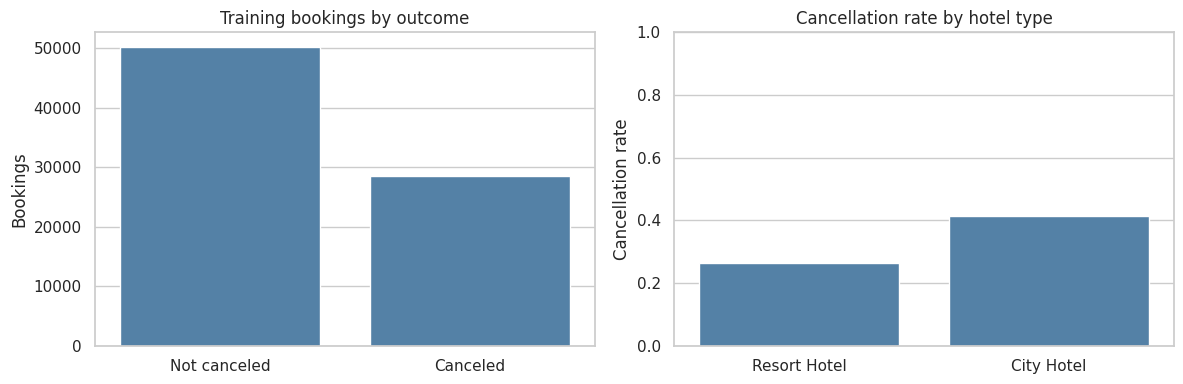

,cancellation_rate,bookings
hotel_type,,
Resort Hotel,0.263,26873
City Hotel,0.414,51717


In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
counts = train_df.is_canceled.value_counts().reindex([0,1],fill_value=0)
sns.barplot(x=["Not canceled","Canceled"],y=counts.values,ax=axes[0],color="steelblue")
axes[0].set(title="Training bookings by outcome",ylabel="Bookings",xlabel="")
hotel_rates = train_df.groupby("hotel_type").is_canceled.agg(["mean","size"]).sort_values("mean")
sns.barplot(x=hotel_rates.index,y=hotel_rates["mean"],ax=axes[1],color="steelblue")
axes[1].set(title="Cancellation rate by hotel type",ylabel="Cancellation rate",xlabel="",ylim=(0,1))
plt.tight_layout();plt.show()
display(hotel_rates.rename(columns={"mean":"cancellation_rate","size":"bookings"}).round(3))


**Interpretation.** In the development cohort, 36.2% of bookings were cancelled, so cancellation is common but still the minority outcome and accuracy alone would be a weak measure. The City Hotel has a much higher cancellation rate (41.4%, 51,717 bookings) than the Resort Hotel (26.3%, 26,873 bookings), and it supplies about two thirds of the bookings. Hotel type may be associated with other factors such as season and distribution channel, so these plots do not isolate a causal effect. They do suggest keeping `hotel_type` as a predictor.

### 3.2 Lead time versus cancellation risk

We use interpretable, pre-specified lead-time bins. Each bar represents the cancellation rate among reservations in that lead-time group; counts are displayed alongside to prevent over-interpreting small groups.

,rate,bookings
lead_time_group,,
0–7 days,0.100,13859
8–30 days,0.265,12594
31–90 days,0.356,20126
91–180 days,0.435,15733
>180 days,0.599,16278


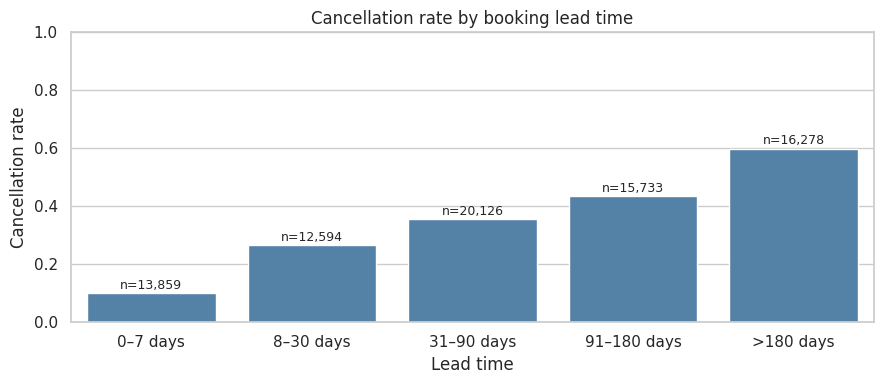

In [ ]:
lead_bins = [-np.inf,7,30,90,180,np.inf]
lead_labels = ["0–7 days","8–30 days","31–90 days","91–180 days",">180 days"]
eda = train_df.copy()
eda["lead_time_group"] = pd.cut(eda.lead_time,bins=lead_bins,labels=lead_labels)
lead_summary = eda.groupby("lead_time_group",observed=False).is_canceled.agg(rate="mean",bookings="size")
display(lead_summary.round(3))
fig,ax=plt.subplots(figsize=(9,4))
sns.barplot(x=lead_summary.index.astype(str),y=lead_summary.rate,ax=ax,color="steelblue")
ax.set(xlabel="Lead time",ylabel="Cancellation rate",title="Cancellation rate by booking lead time",ylim=(0,1))
for i,(rate,n) in enumerate(zip(lead_summary.rate,lead_summary.bookings)):
    if pd.notna(rate):ax.text(i,rate+0.015,f"n={n:,}",ha="center",fontsize=9)
plt.tight_layout();plt.show()


**Interpretation.** Cancellation rises steadily with lead time: 10.0% (0–7 days), 26.5% (8–30), 35.6% (31–90), 43.5% (91–180) and 59.9% (more than 180 days). The relationship is monotonic across the five groups, and every group has at least 12,594 bookings, so it is not driven by small groups. The groups have unequal widths, so the steps are not per-day slopes, but the largest jumps are at the two ends (16.5 points from the first to the second group and 16.4 points from the fourth to the fifth) and the middle steps are smaller (8–9 points). That supports using `log_lead_time` in the linear baseline and motivates checking whether trees capture the pattern better. It describes an association, not a cause.

### 3.3 Stay length and cancellation risk

,rate,bookings
stay_group,,
0–1,0.238,14780
2–3,0.429,36867
4–7,0.341,23554
8–14,0.308,3137
>14,0.583,252


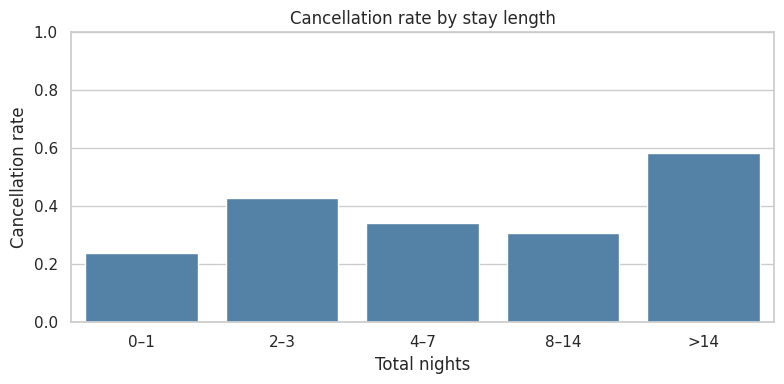

In [ ]:
eda["total_nights"] = eda.stays_in_week_nights + eda.stays_in_weekend_nights
stay_bins=[-np.inf,1,3,7,14,np.inf]
stay_labels=["0–1","2–3","4–7","8–14",">14"]
eda["stay_group"]=pd.cut(eda.total_nights,bins=stay_bins,labels=stay_labels)
stay_summary=eda.groupby("stay_group",observed=False).is_canceled.agg(rate="mean",bookings="size")
display(stay_summary.round(3))
fig,ax=plt.subplots(figsize=(8,4))
sns.barplot(x=stay_summary.index.astype(str),y=stay_summary.rate,ax=ax,color="steelblue")
ax.set(title="Cancellation rate by stay length",xlabel="Total nights",ylabel="Cancellation rate",ylim=(0,1))
plt.tight_layout();plt.show()


**Interpretation.** The pattern for stay length is not monotonic. Cancellation is 23.8% for 0–1 nights (14,780 bookings), jumps to 42.9% for 2–3 nights (36,867), then falls to 34.1% for 4–7 nights (23,554) and 30.8% for 8–14 nights (3,137). Stays longer than 14 nights show the highest rate, 58.3%, but this rests on only 252 bookings (0.3% of the cohort), so we do not read much into it. A single linear term in stay length would miss this rise and fall, so stay length is another case where a tree could help. Stay length is probably also entangled with hotel type and season, which this plot does not separate.

### 3.4 EDA summary

In the development cohort, 36.2% of bookings were cancelled, so cancellation is common but remains the minority outcome. The City Hotel (41.4%, 51,717 bookings) cancels far more often than the Resort Hotel (26.3%, 26,873 bookings). Cancellation rises steadily with lead time, from 10.0% for 0–7 days to 59.9% for more than 180 days, and every lead-time group has at least 12,594 bookings. Stay length follows a rise-and-fall pattern, peaking at 42.9% for 2–3 nights, and the highest rate (58.3% for more than 14 nights) rests on only 252 bookings. All of these are descriptive associations that guide feature choices, such as `log_lead_time` and `hotel_type`, and they do not show that any of these factors causes cancellation.

## Section 4 — Shared Modeling Artifacts

The leakage review, the feature list and the finalized dataset are in Sections 2.6 and 2.7. This section saves the shared split so every model is evaluated on identical rows.

### 4.1 Shared modeling artifacts

Save the split and feature names so that all models are not inadvertently evaluated on different observations. The exported CSV files include `arrival_date` for chronological validation but exclude outcome-revealing predictors. `y` remains a separate target.

In [ ]:
artifact_dir=Path("outputs");artifact_dir.mkdir(exist_ok=True)
train_export=X_train.copy();train_export["is_canceled"]=y_train.to_numpy();train_export["arrival_date"]=train_df.arrival_date.to_numpy()
test_export=X_test.copy();test_export["is_canceled"]=y_test.to_numpy();test_export["arrival_date"]=test_df.arrival_date.to_numpy()
train_export.to_csv(artifact_dir/"train_shared.csv",index=False)
test_export.to_csv(artifact_dir/"test_shared.csv",index=False)
print("Saved shared training and test cohorts in",artifact_dir)


Saved shared training and test cohorts in outputs


## Section 5 — Ridge Logistic Regression Baseline

**Baseline checkpoint status.** This section runs the pipeline end to end and produces one baseline result with an error bar from the **development cohort only** (July 2015 to December 2016). The 2017 test cohort is sealed (`RUN_FINAL_TEST = False`) and is scored once, after all models are tuned.

The baseline is **L2-penalized (ridge) logistic regression**. Country, agent and company add hundreds of one-hot columns, so an unpenalized fit could overfit. The penalty strength `C` (the inverse of the penalty weight) is chosen on a log grid by mean validation log loss over four expanding windows. Rare category levels are grouped inside each training window.

We separate **(1) tuning**, **(2) probability evaluation** (log loss is primary, ROC-AUC secondary), and **(3) threshold diagnostics** (precision, recall, F1, accuracy and the confusion matrix at 0.5, which go to an appendix). Imputation, scaling, one-hot encoding and rare-level grouping all sit inside the sklearn Pipeline and are refit on each training window. Hyperparameters and thresholds are never chosen on the held-out test cohort.

### Training progress indicators

The following helper uses `tqdm` to show progress during parallel cross-validation searches. Progress counts completed CV fits; the final full-development refit may continue briefly after the bar reaches 100%. Bootstrap resampling also displays progress.

In [ ]:
from tqdm.auto import tqdm
from contextlib import contextmanager
from joblib import parallel

@contextmanager
def tqdm_joblib(progress_bar):
    """Show joblib/sklearn parallel CV progress using tqdm."""
    original_callback = parallel.BatchCompletionCallBack

    class TqdmBatchCompletionCallback(original_callback):
        def __call__(self, *args, **kwargs):
            progress_bar.update(self.batch_size)
            return super().__call__(*args, **kwargs)

    parallel.BatchCompletionCallBack = TqdmBatchCompletionCallback
    try:
        yield progress_bar
    finally:
        parallel.BatchCompletionCallBack = original_callback
        progress_bar.close()

def fit_search_with_progress(search, X, y, label):
    # One progress unit per cross-validation fit; final refit occurs afterward.
    from sklearn.model_selection import ParameterGrid
    if hasattr(search, "param_grid"):
        n_candidates = len(ParameterGrid(search.param_grid))
    else:
        n_candidates = search.n_iter
    total = n_candidates * search.cv.get_n_splits() if hasattr(search.cv, "get_n_splits") else n_candidates * len(search.cv)
    with tqdm_joblib(tqdm(total=total, desc=label, unit="CV fit")):
        search.fit(X, y)
    return search


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
from sklearn.metrics import (log_loss,precision_score,recall_score,f1_score,accuracy_score,
                             confusion_matrix,roc_auc_score,roc_curve,ConfusionMatrixDisplay)

MIN_LEVEL_COUNT = 30   # levels with fewer training rows are grouped as "infrequent"

num_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
cat_pipeline = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
                         # min_frequency is counted on the rows the pipeline is fitted on, i.e. the
                         # training window only; unseen levels in validation go to "infrequent".
                         ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                  min_frequency=MIN_LEVEL_COUNT))])
preprocessor = ColumnTransformer([("num", num_pipeline, numeric_features),
                                  ("cat", cat_pipeline, categorical_features)])
# LogisticRegression uses an L2 (ridge) penalty by default; C = 1 / penalty weight.
logistic_pipeline = Pipeline([("preprocessor", preprocessor),
                              ("classifier", LogisticRegression(max_iter=3000, random_state=SEED))])

### 5.1 Expanding-window cross-validation on arrival cohorts

We use four **quarterly validation windows** in 2016, each preceded by all earlier arrival months in the development cohort. This keeps entire arrival months together and follows the proposal's time-aware validation plan. These folds assess later arrival cohorts but cannot fully reconstruct information available at booking creation.


In [ ]:
# Four prespecified expanding-window folds, validating on successive 2016 quarters.
cv_periods = [
    ("2016-01-01", "2016-04-01"),
    ("2016-04-01", "2016-07-01"),
    ("2016-07-01", "2016-10-01"),
    ("2016-10-01", "2017-01-01"),
]
cv_splits = []
for start, end in cv_periods:
    train_idx = np.flatnonzero((train_df["arrival_date"] < pd.Timestamp(start)).to_numpy())
    val_idx = np.flatnonzero(((train_df["arrival_date"] >= pd.Timestamp(start)) &
                              (train_df["arrival_date"] < pd.Timestamp(end))).to_numpy())
    assert len(train_idx) > 0 and len(val_idx) > 0
    assert train_df.iloc[train_idx].arrival_date.max() < train_df.iloc[val_idx].arrival_date.min()
    cv_splits.append((train_idx, val_idx))
    print(f"Train through {train_df.iloc[train_idx].arrival_date.max().date()} "
          f"({len(train_idx):,} rows) -> validate {start} to {end} ({len(val_idx):,} rows)")

# Save these fold indices so every model uses the same windows.
np.savez(artifact_dir / "shared_cv_indices.npz",
         **{f"train_{i}": tr for i, (tr, va) in enumerate(cv_splits)},
         **{f"val_{i}": va for i, (tr, va) in enumerate(cv_splits)})


Train through 2015-12-31 (21,967 rows) -> validate 2016-01-01 to 2016-04-01 (10,951 rows)
Train through 2016-03-31 (32,918 rows) -> validate 2016-04-01 to 2016-07-01 (16,190 rows)
Train through 2016-06-30 (49,108 rows) -> validate 2016-07-01 to 2016-10-01 (15,006 rows)
Train through 2016-09-30 (64,114 rows) -> validate 2016-10-01 to 2017-01-01 (14,476 rows)


### 5.2 Model selection: ridge penalty over a log grid

We compare `C` on a log grid from 1e-4 to 1e2 (13 values) by the mean **validation** log loss over the four expanding windows. Lower is better. `GridSearchCV(scoring="neg_log_loss")` maximizes negative log loss, so scores are negated for reporting. The first earlier run chose the smallest `C` in its grid, so the grid now extends lower; we check below that the chosen `C` is not on the grid boundary. `refit=True` then fits the chosen pipeline on the full development cohort. The test cohort is not involved.

In [ ]:
C_GRID = list(np.logspace(-4, 2, 13))
param_grid = {"classifier__C": C_GRID}
search = GridSearchCV(logistic_pipeline, param_grid=param_grid, scoring="neg_log_loss",
                      cv=cv_splits, n_jobs=-1, refit=True, return_train_score=True)
fit_search_with_progress(search, X_train, y_train, "Ridge logistic CV")
best_C = float(search.best_params_["classifier__C"])
print("Best C:", best_C)
print("Best mean validation log loss:", round(-search.best_score_, 4))
if best_C in (C_GRID[0], C_GRID[-1]):
    print("WARNING: best C is on the grid boundary; extend the grid before trusting it.")
logistic_model = search.best_estimator_

Ridge logistic CV:   0%|          | 0/52 [00:00<?, ?CV fit/s]

Best C: 0.0031622776601683794
Best mean validation log loss: 0.4116


#### 5.2.1 Validation log loss per window

The professor asked for the spread across windows, not only the mean. Each row is one value of `C`; columns are the four validation windows. The error bar on the mean is the standard error over the four windows (SD / sqrt(4)), which is rough with only four windows, so the block bootstrap in 5.2c adds a second interval.

In [ ]:
cvr = pd.DataFrame(search.cv_results_)
n_win = len(cv_splits)
win_labels = ["Jan–Mar 2016", "Apr–Jun 2016", "Jul–Sep 2016", "Oct–Dec 2016"]
val_ll = -cvr[[f"split{k}_test_score" for k in range(n_win)]].to_numpy()   # rows: C, cols: windows
best_row = int(search.best_index_)

grid_table = pd.DataFrame(val_ll, index=pd.Index(C_GRID, name="C"), columns=win_labels)
grid_table["mean"] = val_ll.mean(axis=1)
grid_table["sd"] = val_ll.std(axis=1, ddof=1)
grid_table["mean_train_log_loss"] = -cvr["mean_train_score"].to_numpy()
display(grid_table.round(4))

per_window = val_ll[best_row]
win_mean = float(per_window.mean())
win_sd = float(per_window.std(ddof=1))
win_se = win_sd / np.sqrt(n_win)
print(f"Chosen C = {best_C:g}")
print("Validation log loss per window:", dict(zip(win_labels, per_window.round(4))))
print(f"Mean = {win_mean:.4f}   SD across windows = {win_sd:.4f}   SE = {win_se:.4f}  (n = {n_win} windows)")

,Jan–Mar 2016,Apr–Jun 2016,Jul–Sep 2016,Oct–Dec 2016,mean,sd,mean_train_log_loss
C,,,,,,,
0.000100,0.5205,0.5390,0.5292,0.5151,0.5260,0.0105,0.4965
0.000316,0.4613,0.4709,0.4753,0.4660,0.4684,0.0060,0.4232
0.001000,0.4205,0.4162,0.4370,0.4382,0.4280,0.0112,0.3645
0.003162,0.4118,0.3847,0.4186,0.4311,0.4116,0.0196,0.3251
0.010000,0.4344,0.3722,0.4144,0.4372,0.4145,0.0300,0.3003
0.031623,0.4793,0.3700,0.4156,0.4474,0.4281,0.0466,0.2851
0.100000,0.5344,0.3709,0.4180,0.4550,0.4446,0.0691,0.2768
0.316228,0.5820,0.3732,0.4207,0.4621,0.4595,0.0894,0.2725
1.000000,0.6135,0.3765,0.4229,0.4647,0.4694,0.1026,0.2706


Chosen C = 0.00316228
Validation log loss per window: {'Jan–Mar 2016': np.float64(0.4118), 'Apr–Jun 2016': np.float64(0.3847), 'Jul–Sep 2016': np.float64(0.4186), 'Oct–Dec 2016': np.float64(0.4311)}
Mean = 0.4116   SD across windows = 0.0196   SE = 0.0098  (n = 4 windows)


#### 5.2.2 Block-bootstrap interval, constant reference, and the baseline figure

We refit the chosen ridge model on each training window to get out-of-window validation probabilities (they must reproduce the table above), pool them, and bootstrap **weekly arrival-date blocks** 2,000 times (seed fixed). A constant forecast (the training cancellation rate) shows how much the model adds. `C` was chosen on these same windows, so the validation numbers are slightly optimistic. The 2017 test cohort is not used. Predictions are saved so the tree and forest models can be compared on identical rows.

Pooled validation log loss = 0.4108; 95% block-bootstrap interval [0.3983, 0.4247] (53 weekly blocks, 2000 resamples, seed 42)
Constant-forecast log loss per window: [0.6259 0.663  0.651  0.6669]  mean 0.6517
ROC-AUC per window: [0.8565 0.9032 0.875  0.8897]


,validation_log_loss,constant_forecast,roc_auc
Jan–Mar 2016,0.4118,0.6259,0.8565
Apr–Jun 2016,0.3847,0.6630,0.9032
Jul–Sep 2016,0.4186,0.6510,0.8750
Oct–Dec 2016,0.4311,0.6669,0.8897


Chosen C = 0.00316228 | windows: mean 0.4116, SD 0.0196, SE 0.0098 | pooled 0.4108, 95% block-bootstrap [0.3983, 0.4247]
Rows: development 78,590, sealed test 40,619, predictors 26, dev cancel rate 0.3622


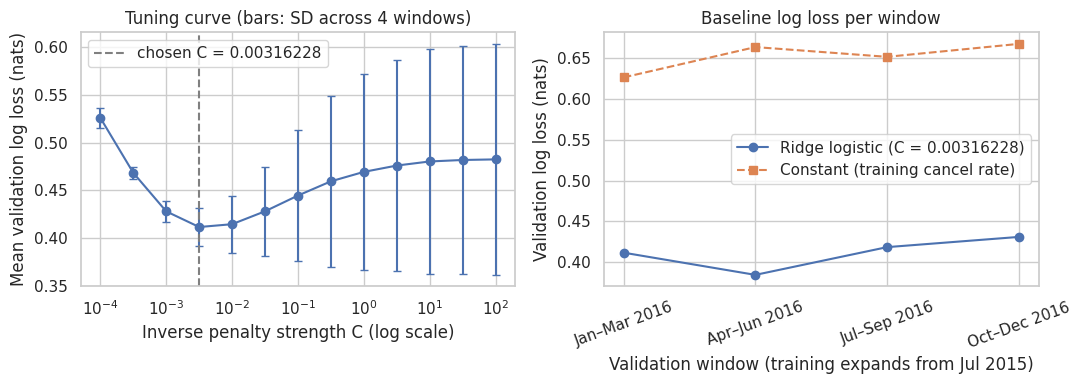

In [ ]:
from sklearn.metrics import roc_auc_score

# 1) Out-of-window predictions with the chosen C (same folds as the grid search)
oof = []
for k, (tr, va) in enumerate(cv_splits):
    m = clone(logistic_pipeline).set_params(classifier__C=best_C).fit(X_train.iloc[tr], y_train.iloc[tr])
    p = m.predict_proba(X_train.iloc[va])[:, 1]
    oof.append(pd.DataFrame({"window": win_labels[k],
                             "arrival_date": train_df["arrival_date"].iloc[va].to_numpy(),
                             "y_true": y_train.iloc[va].to_numpy(),
                             "ridge_probability": p}))
oof = pd.concat(oof, ignore_index=True)
refit_ll = np.array([log_loss(g.y_true, g.ridge_probability, labels=[0, 1]) for _, g in oof.groupby("window", sort=False)])
assert np.allclose(refit_ll, per_window, atol=1e-3), (refit_ll, per_window)

# 2) Weekly arrival-date block bootstrap of the pooled validation log loss
eps = 1e-15
p = np.clip(oof.ridge_probability.to_numpy(), eps, 1 - eps)
loss = -(oof.y_true.to_numpy() * np.log(p) + (1 - oof.y_true.to_numpy()) * np.log(1 - p))
block_id, _ = pd.factorize(pd.to_datetime(oof.arrival_date).dt.to_period("W").astype(str))
n_blocks = block_id.max() + 1
block_sum = np.bincount(block_id, weights=loss, minlength=n_blocks)
block_cnt = np.bincount(block_id, minlength=n_blocks)
rng = np.random.default_rng(SEED)
draw = rng.integers(0, n_blocks, size=(2000, n_blocks))
boot = block_sum[draw].sum(axis=1) / block_cnt[draw].sum(axis=1)
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
pooled_ll = float(loss.mean())
print(f"Pooled validation log loss = {pooled_ll:.4f}; 95% block-bootstrap interval [{ci_lo:.4f}, {ci_hi:.4f}] "
      f"({n_blocks} weekly blocks, 2000 resamples, seed {SEED})")

# 3) Reference: constant forecast (training cancellation rate) and per-window AUC
const_ll = []
for tr, va in cv_splits:
    pc = float(np.clip(y_train.iloc[tr].mean(), eps, 1 - eps))
    const_ll.append(log_loss(y_train.iloc[va], np.full(len(va), pc), labels=[0, 1]))
auc_w = [roc_auc_score(g.y_true, g.ridge_probability) for _, g in oof.groupby("window", sort=False)]
print("Constant-forecast log loss per window:", np.round(const_ll, 4), " mean", round(float(np.mean(const_ll)), 4))
print("ROC-AUC per window:", np.round(auc_w, 4))

# 4) Save predictions for paired comparisons across models
oof.to_csv(artifact_dir / "ridge_validation_predictions.csv", index=False)
summary = pd.DataFrame({"validation_log_loss": per_window, "constant_forecast": const_ll, "roc_auc": auc_w},
                       index=win_labels)
display(summary.round(4))
print(f"Chosen C = {best_C:g} | windows: mean {win_mean:.4f}, SD {win_sd:.4f}, SE {win_se:.4f} | "
      f"pooled {pooled_ll:.4f}, 95% block-bootstrap [{ci_lo:.4f}, {ci_hi:.4f}]")
print(f"Rows: development {len(train_df):,}, sealed test {len(test_df):,}, predictors {len(features)}, "
      f"dev cancel rate {y_train.mean():.4f}")

# 5) First version of the figure
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
Cs = np.array(C_GRID)
ax[0].errorbar(Cs, grid_table["mean"], yerr=grid_table["sd"], fmt="o-", capsize=3)
ax[0].axvline(best_C, color="gray", ls="--", label=f"chosen C = {best_C:g}")
ax[0].set(xscale="log", xlabel="Inverse penalty strength C (log scale)",
          ylabel="Mean validation log loss (nats)", title="Tuning curve (bars: SD across 4 windows)")
ax[0].legend()
ax[1].plot(win_labels, per_window, "o-", label=f"Ridge logistic (C = {best_C:g})")
ax[1].plot(win_labels, const_ll, "s--", label="Constant (training cancel rate)")
ax[1].set(xlabel="Validation window (training expands from Jul 2015)",
          ylabel="Validation log loss (nats)", title="Baseline log loss per window")
ax[1].tick_params(axis="x", rotation=20); ax[1].legend()
plt.tight_layout(); plt.savefig("baseline.png", dpi=150, bbox_inches="tight"); plt.show()

### 5.3 Coefficient interpretation

Logistic coefficients are changes in **log odds**, not direct changes in cancellation probability. They are conditional on the other encoded features and are not causal effects. For numeric features, coefficients correspond to a one-standard-deviation change after scaling; categorical coefficients are relative to the encoding scheme. We report large absolute coefficients for exploration, not as a definitive causal feature ranking.

In [ ]:
feature_names=logistic_model.named_steps["preprocessor"].get_feature_names_out()
coef=logistic_model.named_steps["classifier"].coef_.ravel()
coef_table=pd.DataFrame({"feature":feature_names,"coefficient":coef,"odds_ratio":np.exp(np.clip(coef,-30,30))})
display(coef_table.reindex(coef_table.coefficient.abs().sort_values(ascending=False).index).head(15).round(3))


,feature,coefficient,odds_ratio
75,cat__country_PRT,1.570,4.809
116,cat__deposit_type_Non Refund,1.206,3.339
115,cat__deposit_type_No Deposit,-1.125,0.325
9,num__previous_cancellations,1.086,2.962
12,num__required_car_parking_spaces,-0.893,0.410
130,cat__agent_ 9,0.871,2.389
0,num__log_lead_time,0.738,2.091
217,cat__agent_ 240,0.670,1.954
13,num__total_of_special_requests,-0.647,0.523
47,cat__country_DEU,-0.480,0.619


### 5.4 Final held-out test evaluation (SEALED until all models are tuned)

**Do not run before the final comparison.** The code below is skipped while `RUN_FINAL_TEST = False` (set in section 2.5). When all preprocessing, features, hyperparameters and thresholds are frozen, set the flag to `True` and run this cell once.

Primary outcome: held-out test log loss. Secondary: ROC-AUC. Threshold-based metrics (precision, recall, F1, accuracy at 0.5) and the confusion matrix are diagnostics for the appendix.

In [ ]:
if not RUN_FINAL_TEST:
    print('Test cohort is sealed (RUN_FINAL_TEST = False). Skipping final evaluation.')
else:
    logistic_proba=logistic_model.predict_proba(X_test)[:,1]
    logistic_pred=(logistic_proba>=0.5).astype(int)
    logistic_metrics={
        "log_loss_nll":log_loss(y_test,logistic_proba),
        "precision":precision_score(y_test,logistic_pred,zero_division=0),
        "recall":recall_score(y_test,logistic_pred,zero_division=0),
        "f1":f1_score(y_test,logistic_pred,zero_division=0),
        "accuracy":accuracy_score(y_test,logistic_pred),
        "roc_auc":roc_auc_score(y_test,logistic_proba)
    }
    display(pd.DataFrame([logistic_metrics],index=["Logistic Regression"]).round(4))
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    ConfusionMatrixDisplay.from_predictions(y_test,logistic_pred,display_labels=["Not canceled","Canceled"],ax=axes[0],colorbar=False)
    axes[0].set_title("Logistic regression confusion matrix")
    fpr,tpr,_=roc_curve(y_test,logistic_proba)
    axes[1].plot(fpr,tpr,label=f"Logistic (AUC={logistic_metrics['roc_auc']:.3f})")
    axes[1].plot([0,1],[0,1],"--",color="gray",label="Random ranking")
    axes[1].set(xlabel="False positive rate",ylabel="True positive rate",title="ROC curve")
    axes[1].legend();plt.tight_layout();plt.show()

    # Save aligned row-level probabilities for paired model comparison / bootstrap.
    logistic_predictions = pd.DataFrame({
        "arrival_date": test_df["arrival_date"].to_numpy(),
        "y_true": y_test.to_numpy(),
        "logistic_probability": logistic_proba,
        "logistic_prediction_05": logistic_pred,
    })
    logistic_predictions.to_csv(artifact_dir / "logistic_test_predictions.csv", index=False)
    print("Saved aligned test predictions to", artifact_dir / "logistic_test_predictions.csv")

Test cohort is sealed (RUN_FINAL_TEST = False). Skipping final evaluation.
